# **Restriceted Boltzmann Machine - Unsupervised Learning**

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

In [ ]:
DATASET_PATH = "./Dataset"
IMG_SIZE = 30 # ini aslinya 300, tapi dikecilin biar lebih ringan

## **Load Dataset**

In [3]:
images = []
for nama_file in os.listdir(DATASET_PATH):
    path = os.path.join(DATASET_PATH, nama_file)
    if nama_file == "Thumbs.db":
        continue
    img = tf.keras.preprocessing.image.load_img(path, target_size=(IMG_SIZE, IMG_SIZE))
    images.append(np.array(img))

# Normalize
data = np.array(images, dtype=np.float32) / 255
data = data.reshape(len(data), -1)
print("Data Shape: ", data.shape)

# Split
data = tf.random.shuffle(data, seed=42).numpy() # untuk random urutan data
batas = int(len(data) * 0.6)
train_data = data[:batas]
test_data = data[batas:]
print("Train: ", (train_data.shape))
print("Test: ", (test_data.shape))

Data Shape:  (628, 2700)
Train:  (376, 2700)
Test:  (252, 2700)


## **Creating RBM (Paling penting)**

In [4]:
class RBM:
    def __init__(self, input_size, output_size, lr=0.001, batch_size=32, epochs=200):
        self.input_size = input_size
        self.output_size = output_size
        self.lr = lr
        self.batch_size = batch_size
        self.epochs = epochs

        # Initialize weights and biases
        self.w = tf.zeros([input_size, output_size], tf.float32)
        self.vb = tf.zeros([input_size], tf.float32)  # visible bias
        self.hb = tf.zeros([output_size], tf.float32)  # hidden bias
    
    def probability_h_given_v(self, visible):
        return tf.nn.sigmoid(tf.matmul(visible, self.w) + self.hb)

    def probability_v_given_h(self, hidden):
        return tf.nn.sigmoid(tf.matmul(hidden, tf.transpose(self.w)) + self.vb) # transpose karena w adalah matriks input_size x output_size vb = 1x4, hb = 1x3, jadi ukurannya gamau berubah

    # fully randomize dia gatau apapun
    def sample_probability(self, probs):
        return tf.nn.relu(tf.sign(probs - tf.random.uniform(tf.shape(probs)))) # random karena gatau konteks, jadi random aja

    def update_weight_and_bias(self, v0, h0, v1, h1): # cara kerjanya bolak balik]
        n = tf.cast(tf.shape(v0)[0], tf.float32) # Cari tahu ukuran batch
        positive_gradient = tf.matmul(tf.transpose(v0), h0) # v0 adalah input, h0 adalah output [Positif gradient = data asli]
        negative_gradient = tf.matmul(tf.transpose(v1), h1) # v1 adalah input, h1 adalah output [data rekonstruksi]

        # Rumus: Contransive Divergence = (positive_gradient - negative_gradient) / n [rumus untuk update weight dan bias]
        self.w += self.lr * (positive_gradient - negative_gradient) / n
        self.vb += self.lr * tf.reduce_mean(v0 - v1, 0)
        self.hb += self.lr * tf.reduce_mean(h0 - h1, 0)

    # training
    def train(self, x_train, epochs):
        x_train = tf.constant(x_train, tf.float32) # agar datanya konstan
        dataset = tf.data.Dataset.from_tensor_slices(x_train).batch(self.batch_size) # agar datanya bisa di batch
        losses = []
        for epoch in range(epochs):
            batch_losses = []
            for batch in dataset:
                # Data asli -> Hidden
                h0 = self.probability_h_given_v(batch) # hitung probabilitas hidden layer
                # Hidden -> Rekonstruksi
                v1 = self.sample_probability(self.probability_v_given_h(h0)) # hitung probabilitas visible layer
                # Rekonstruksi -> hidden
                h1 = self.probability_h_given_v(v1) # hitung probabilitas hidden layer

                # Backpropagation
                self.update_weight_and_bias(batch, h0, v1, h1) # update
                batch_losses.append(tf.reduce_mean(tf.square(batch - v1)).numpy()) # hitung loss

            loss = float(np.mean(batch_losses)) # hitung loss rata-rata
            losses.append(loss)
            if(epoch + 1) % 10 == 0 or epoch == 0:
                print(f"Epoch: {epoch + 1}/{epochs} | Loss: {loss:.4f}")

        return losses

    # Reconstruct
    def reconstruct(self, x):
        x = tf.constant(x, tf.float32)
        return self.probability_v_given_h(self.probability_h_given_v(x))

## **Training**

In [8]:
INPUT_SIZE = train_data.shape[1]
model = RBM(INPUT_SIZE, 1000, lr=0.001, batch_size=32)
losses = model.train(train_data, epochs=10)

Epoch: 1/10 | Loss: 0.3505
Epoch: 10/10 | Loss: 0.3353


## **Evaluation**

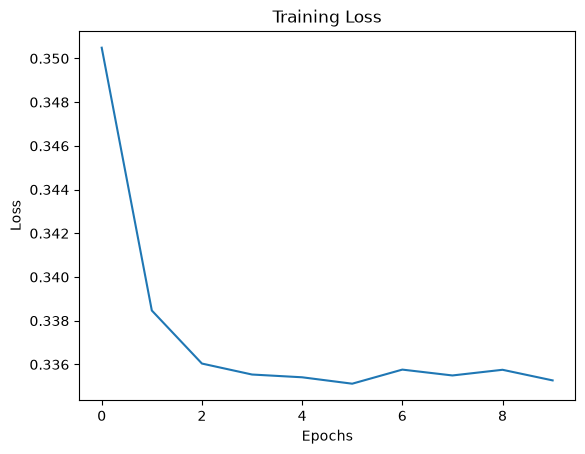

In [9]:
plt.plot(losses)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

## **Reconstruct**

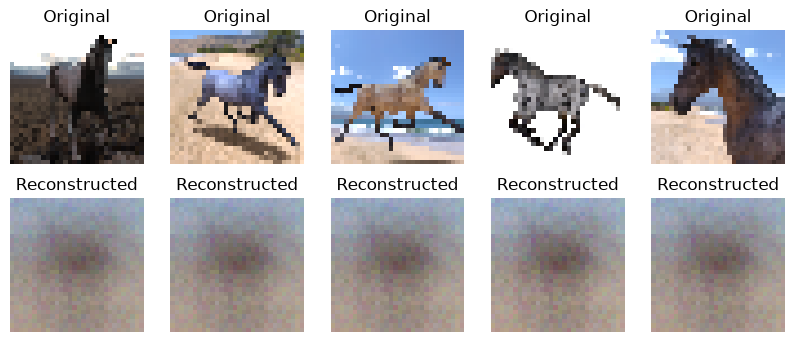

In [10]:
def rbm_reconstruct(x, n=5):
    hasil = model.reconstruct(x[:n]).numpy()
    plt.figure(figsize=(2*n, 4))
    for i in range(n):
        plt.subplot(2, n, i + 1)
        plt.imshow(x[i].reshape(IMG_SIZE, IMG_SIZE, 3))
        plt.axis('off')
        plt.title("Original")
        
        plt.subplot(2, n, i + 1 + n)
        plt.imshow(np.clip(hasil[i], 0, 1).reshape(IMG_SIZE, IMG_SIZE, 3))
        plt.axis('off')
        plt.title("Reconstructed")
    plt.show()

rbm_reconstruct(test_data, n=5)
        